# Load libraries

In [1]:
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import os
from os import listdir
from os.path import isfile, join
import tifffile as tiff # you might have to install this with 'pip install tifffile'

# Print files in the current working directory (cwd)

In [2]:
folder = os.getcwd()
files = listdir(folder)

for i, f_i in enumerate(files):
    print(i, f_i)

0 12.tif
1 389.tif
2 392.tif
3 430.tif
4 502.tif
5 570.tif
6 81.tif
7 92.tif
8 Load_and_plot_Tiff.ipynb


# Read and plot image file

In [23]:
# Convert images to arrays
img= tiff.imread(files[6])
img_array = np.array(img).astype('float64')
print(np.shape(img_array))

(1080, 1440, 3)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0..994].


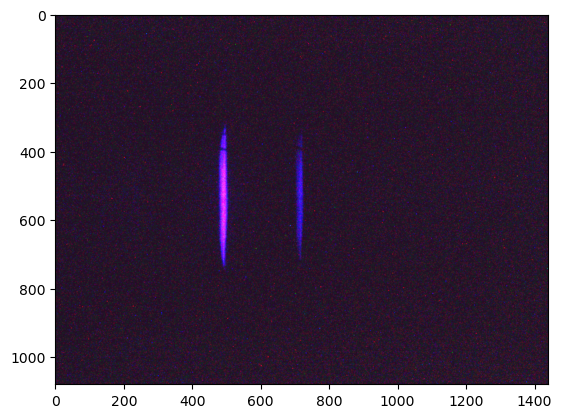

In [24]:
# Plot example image
plt.imshow(img, vmin=1000,vmax=0) 

# Plot linecut

In [13]:
y_max, x_max, c_max = np.shape(img_array)

x = np.linspace(0, x_max - 1, x_max)

y = 550

# chose color channel
c = 1

cts = (img_array[y, :, 0] + img_array[y, :, 1] + img_array[y, :, 2]) / 3

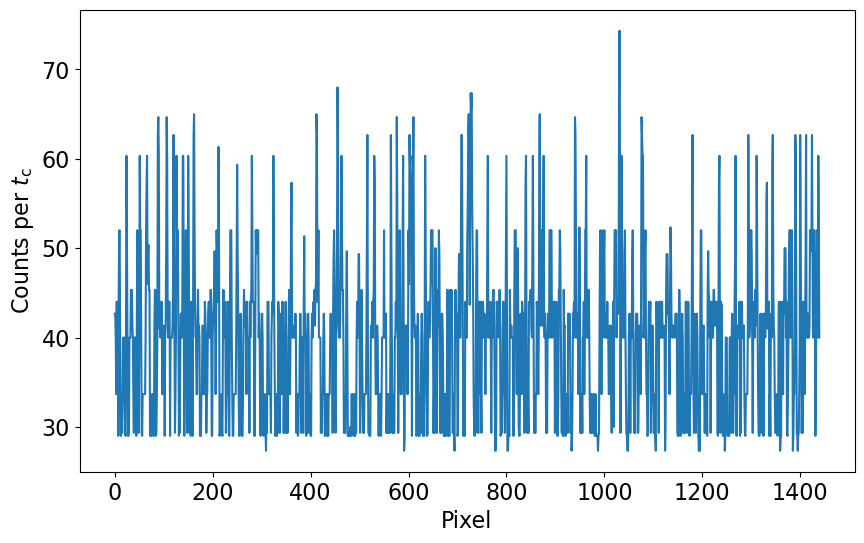

In [14]:
# Plot Data
plt.figure(
    num=1,
    figsize=(10,6),
    facecolor='white')
plt.xlabel(r'Pixel', fontsize=16)
plt.ylabel(r'Counts per $t_\mathrm{c}$', fontsize=16)
plt.plot(x, cts)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

In [9]:
popt = np.loadtxt("../../popt.txt")
k0 = popt[0]
b = popt[1]
d = popt[3]
p_cent = 720
print(k0)
print(b)
print(d)

def lamda(pp, kk):
    return b * ((kk - k0) - (pp - p_cent) / d)

1126.0
-0.7850772089259566
25.77604083290055


In [10]:
print(lamda(720, 502))

489.8881783697969
